# 300 sayım adresi 12.000 adresi nasıl temsil eder?

Envanter ekibi hareketi yavaş adresleri de görmek için hızlı, orta ve yavaş dönen adreslerin her birinden 100 adres seçiyor. Rapor ekibi ham örneklem oranını depo geneline taşımak istiyor. İkinci durumda bazı adresler yeniden sayılmadan rapor kapanıyor.

Karar: Depo genelindeki sayım farkı %6 inceleme eşiğine göre ne söylüyor? Karar için hangi adresler takip edilmeli?

Veriler sentetiktir. Her senaryo sabit tohumla aynı veriyi yeniden oluşturur. CSV dosyaları örnek çıktıdır. Bir CSV’yi değiştirmen bu defterin verisini otomatik değiştirmez.


In [1]:
import numpy as np
import pandas as pd
from scipy import stats
from scipy.special import expit
import matplotlib.pyplot as plt

BLUE, ORANGE, GREEN, GRAY = '#2457ad', '#ac452c', '#197254', '#64748b'
plt.rcParams.update({'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'axes.axisbelow': True, 'grid.alpha': .19})

def table(frame, title):
    return dict(title=title, columns=frame.columns.tolist(),
                rows=frame.astype(object).where(frame.notna(), None).values.tolist())

def inventory_audit(scenario='default'):
    rng = np.random.default_rng(72101)
    configs = [('Hızlı dönen',8000,0.035,100),('Orta dönen',3000,0.075,100),('Yavaş dönen',1000,0.17,100)]
    selections = []
    rows = []
    for label,N,p,n in configs:
        error = rng.binomial(1,p,N)
        idx = rng.choice(N,n,replace=False)
        sampled = error[idx]
        draw = rng.random(n)
        lost = (draw < np.where(sampled==1,.54,.09)) if scenario == 'nonresponse' else np.zeros(n,dtype=bool)
        visible = np.where(lost,np.nan,sampled)
        observed = np.nansum(visible)
        missing = lost.sum()
        lower = observed/n
        upper = (observed+missing)/n
        rows.append([label,N,n,int(observed),int(missing),lower,upper,N/12000])
        selections.extend([[label,int(i+1),None if m else int(v)] for i,m,v in zip(idx,lost,sampled)])
    detail = pd.DataFrame(rows,columns=['Tabaka','Evren N','Çekilen n','Bulunan hata','Eksik denetim','Alt oran','Üst oran','Evren ağırlığı'])
    raw = pd.DataFrame(selections,columns=['Tabaka','Adres no (tabaka içi)','Sayım farkı · 0/1'])
    w = detail['Evren ağırlığı'].to_numpy()
    lows = detail['Alt oran'].to_numpy()
    highs = detail['Üst oran'].to_numpy()
    low,high = w @ lows,w @ highs
    n = detail['Çekilen n'].to_numpy()
    N = detail['Evren N'].to_numpy()
    var = np.sum(w**2*(1-n/N)*lows*(1-lows)/(n-1))
    ci = [max(0,low-1.96*np.sqrt(var)),min(1,low+1.96*np.sqrt(var))]
    complete = scenario=='default'
    crude = raw['Sayım farkı · 0/1'].mean()
    target = .06
    fig, ax = plt.subplots(figsize=(8.6,4.4),layout='constrained')
    x = np.arange(3)
    ax.errorbar(x,(lows+highs)*50,(highs-lows)*50,fmt='o',capsize=7,color=BLUE,label='Örneklem durumu sınırları')
    ax.set(xticks=x,xticklabels=detail.Tabaka,ylabel='Sayım farkı · %',title='Her tabakada örneklem ve bilinmeyen denetimler')
    for i,a in enumerate(w):
        ax.annotate(f'Evren payı %{a*100:.1f}',(i,highs[i]*100),xytext=(0,10),textcoords='offset points',ha='center')
    ax.set_ylim(0,max(highs)*100+6)
    fig2, ax2 = plt.subplots(figsize=(8.6,3.25),layout='constrained')
    bounds = ci if complete else [low,high]
    ax2.errorbar([(bounds[0]+bounds[1])*50],[1],xerr=[(bounds[1]-bounds[0])*50],fmt='o',capsize=6,color=BLUE)
    ax2.axvline(target*100,color=ORANGE,ls='--',label='%6 işletme inceleme eşiği')
    ax2.set(yticks=[],xlabel='Ağırlıklı hata oranı · %',
            title='Tasarım temelli yaklaşık %95 aralık' if complete else 'Cevapsız adresler için duyarlılık sınırı')
    ax2.legend(loc='upper right',fontsize=9)
    decision = (
        f'Adres ağırlığıyla tahmin %{low*100:.2f}. Yaklaşık aralık %{ci[0]*100:.2f}–%{ci[1]*100:.2f}. %6 eşiğine ilişkin kesin karar için aralığın konumunu ve tabaka risklerini birlikte oku.'
        if complete else
        f'Kayıp denetimler için ağırlıklı örneklem oranı %{low*100:.2f}–%{high*100:.2f} arasında. Bu sınırlar örnekleme hatasını içermez. Cevapsız adresleri takip et ve nedenlerini kaydet.'
    )
    return dict(metrics={'Çekilen adres':int(len(raw)),'Evren adresi':12000,'Tamamlananların basit oranı · %':crude*100,
                         'Ağırlıklı tahmin · %':low*100 if complete else 'Cevap eksik',
                         'Aralık türü':'%95 yaklaşık örnekleme' if complete else 'Eksik veri duyarlılığı',
                         'Alt–üst · %':f'{bounds[0]*100:.2f}–{bounds[1]*100:.2f}'},
        tables=[table(detail,'Örneklem hacmi ve evren ağırlığı')],figures=[
          ('Üç tabakanın her birinden 100 adres çekilir, ama evren payları farklıdır.',fig),
          ('İş eşiği aynı kalır. Eksik veri senaryosundaki çizgi güven aralığı değildir.',fig2)],
        frames={'adres_denetimi':raw,'tabaka_ozeti':detail},
        steps=['Adresleri hareket hızına göre birbirini dışlayan üç tabakaya ayır. Her tabakadan yerine koymadan rastgele çek.',
               'Tabaka oranını evren ağırlığı Nₕ/N ile çarp ve topla. Örnekteki eşit n, evrenin üçte birini temsil etmez.',
               'Tam cevapta varyansa sonlu evren düzeltmesi 1−nₕ/Nₕ ekle. Eksik cevapta yalnız tamamlananların oranına güvenme.'],
        decision=decision,limit='Evren çerçevesinin tam ve tabakaların doğru olduğu varsayılır. Yaklaşık normal aralık çok seyrek hata veya küçük tabaka n değerinde zayıf olabilir. Eksik senaryosunda sonuçla ilişkili kayıp simüle edilir, güven aralığı üretilmez.',
        diagnostics={'weight_sum':w.sum(),'weighted_bounds':[low,high],'ci':ci if complete else None,'crude':crude},
        focus=[['Seçim','3 × 100 adres','Her tabakada rastgele'],['Ağırlık','8.000 / 3.000 / 1.000','Evren büyüklüğüne göre'],['Karar',f'%{bounds[0]*100:.2f}–{bounds[1]*100:.2f}','%6 iş eşiğiyle karşılaştır']])


def print_result(result):
    for name, value in result['metrics'].items():
        print(f"{name}: {value}")
    print()
    for t in result['tables']:
        print(t['title'])
        print(pd.DataFrame(t['rows'], columns=t['columns']).to_string(index=False))
        print()
    print('Karar:', result['decision'])
    print('Koşullar:', result['limit'])


## Tam denetim

100’er adreste 2, 8 ve 25 kesin fark bulundu. Evren büyüklükleri 8.000, 3.000 ve 1.000 adres. Eksikleri fark saymadan ağırlıklı hata oranı yüzde kaç?


Çekilen adres: 300
Evren adresi: 12000
Tamamlananların basit oranı · %: 11.666666666666666
Ağırlıklı tahmin · %: 5.416666666666667
Aralık türü: %95 yaklaşık örnekleme
Alt–üst · %: 3.07–7.77

Örneklem hacmi ve evren ağırlığı
     Tabaka  Evren N  Çekilen n  Bulunan hata  Eksik denetim  Alt oran  Üst oran  Evren ağırlığı
Hızlı dönen     8000        100             2              0      0.02      0.02        0.666667
 Orta dönen     3000        100             8              0      0.08      0.08        0.250000
Yavaş dönen     1000        100            25              0      0.25      0.25        0.083333

Karar: Adres ağırlığıyla tahmin %5.42. Yaklaşık aralık %3.07–%7.77. %6 eşiğine ilişkin kesin karar için aralığın konumunu ve tabaka risklerini birlikte oku.
Koşullar: Evren çerçevesinin tam ve tabakaların doğru olduğu varsayılır. Yaklaşık normal aralık çok seyrek hata veya küçük tabaka n değerinde zayıf olabilir. Eksik senaryosunda sonuçla ilişkili kayıp simüle edilir, güven aralığı ü

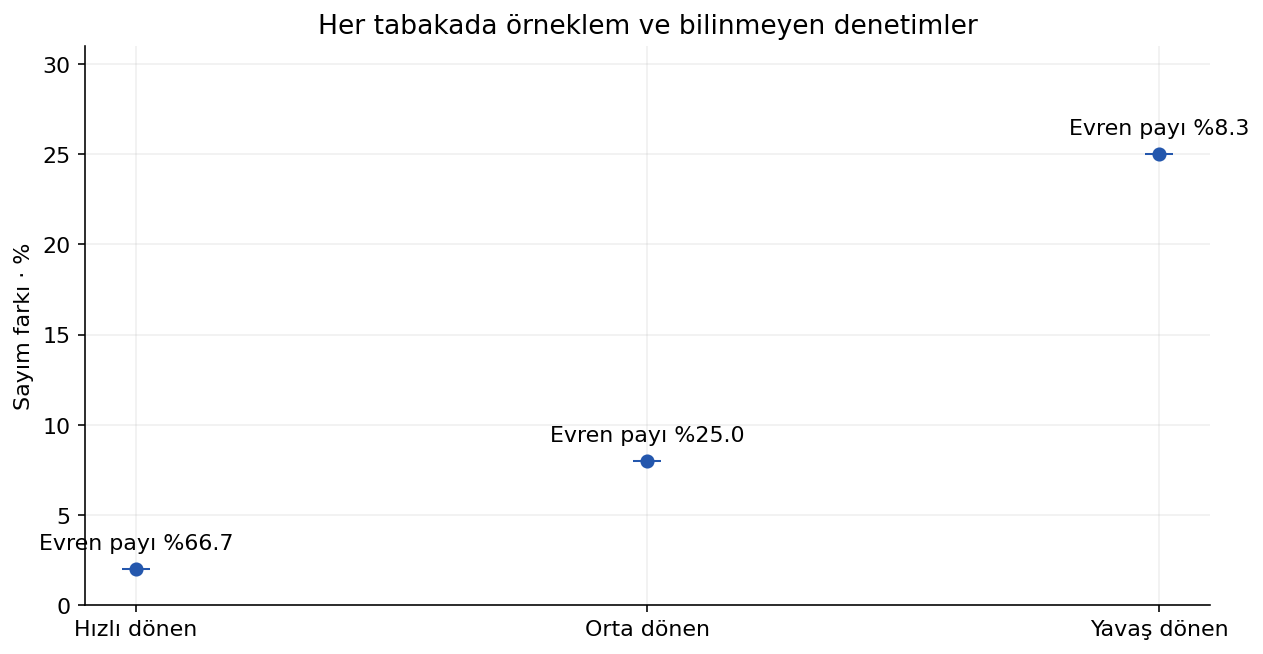

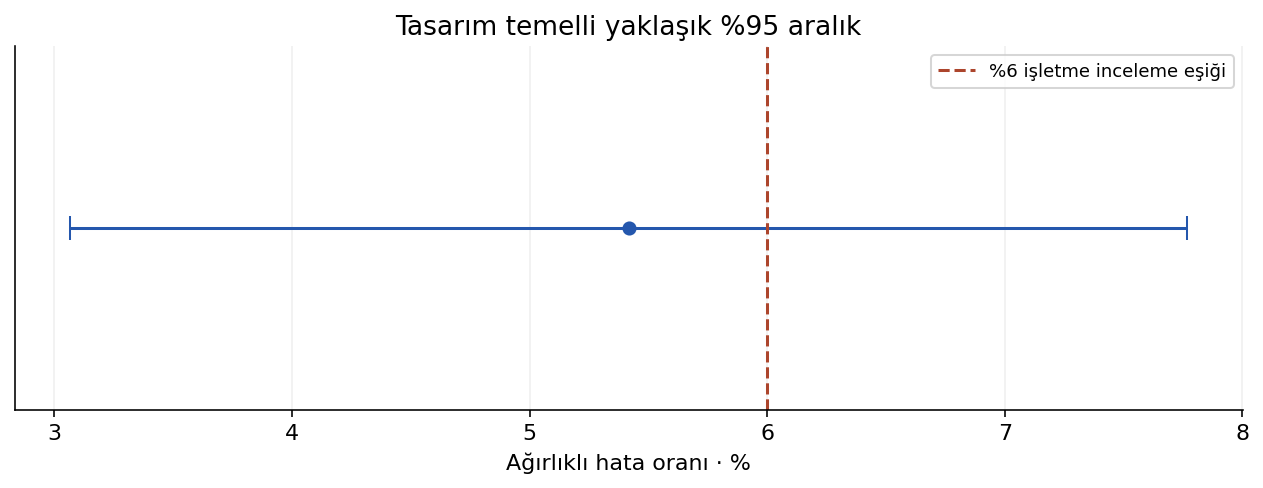

In [2]:
result = inventory_audit('default')
print_result(result)
plt.show()


## Adreslerin bir kısmı denetlenemedi

100’er adreste 2, 1 ve 9 kesin fark bulundu. Evren büyüklükleri 8.000, 3.000 ve 1.000 adres. Eksikleri fark saymadan ağırlıklı hata oranı yüzde kaç?


Çekilen adres: 300
Evren adresi: 12000
Tamamlananların basit oranı · %: 4.761904761904762
Ağırlıklı tahmin · %: Cevap eksik
Aralık türü: Eksik veri duyarlılığı
Alt–üst · %: 2.33–15.08

Örneklem hacmi ve evren ağırlığı
     Tabaka  Evren N  Çekilen n  Bulunan hata  Eksik denetim  Alt oran  Üst oran  Evren ağırlığı
Hızlı dönen     8000        100             2             11      0.02      0.13        0.666667
 Orta dönen     3000        100             1             14      0.01      0.15        0.250000
Yavaş dönen     1000        100             9             23      0.09      0.32        0.083333

Karar: Kayıp denetimler için ağırlıklı örneklem oranı %2.33–%15.08 arasında. Bu sınırlar örnekleme hatasını içermez. Cevapsız adresleri takip et ve nedenlerini kaydet.
Koşullar: Evren çerçevesinin tam ve tabakaların doğru olduğu varsayılır. Yaklaşık normal aralık çok seyrek hata veya küçük tabaka n değerinde zayıf olabilir. Eksik senaryosunda sonuçla ilişkili kayıp simüle edilir, güven aral

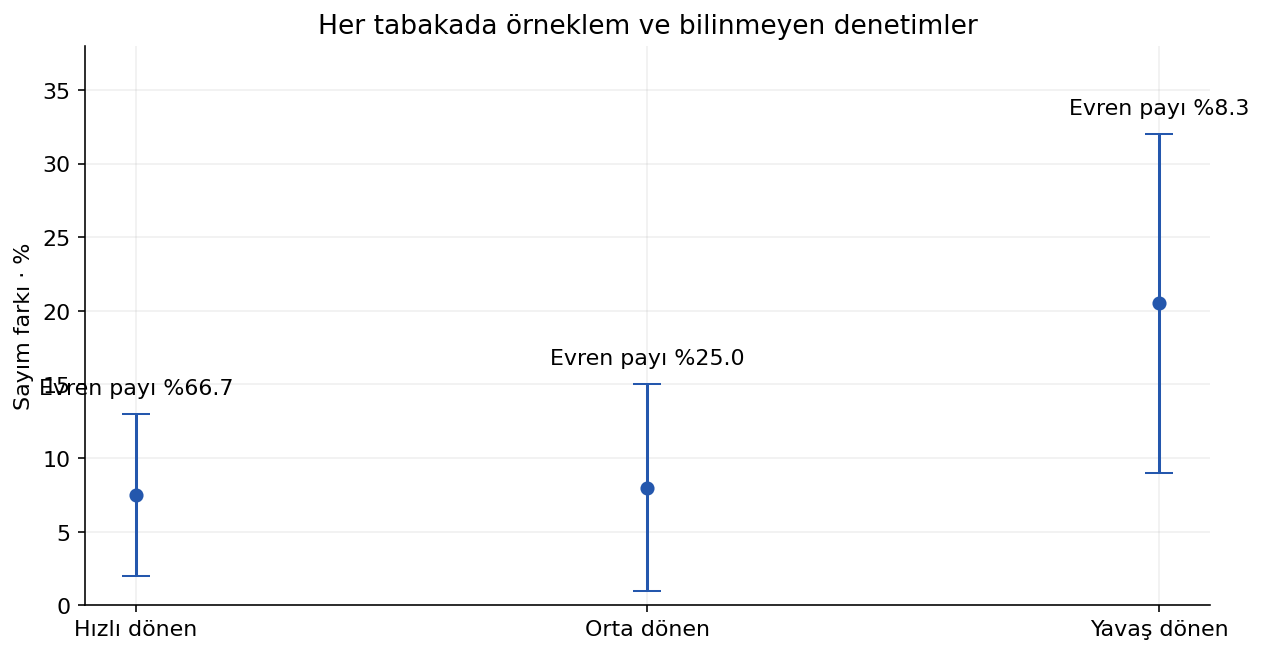

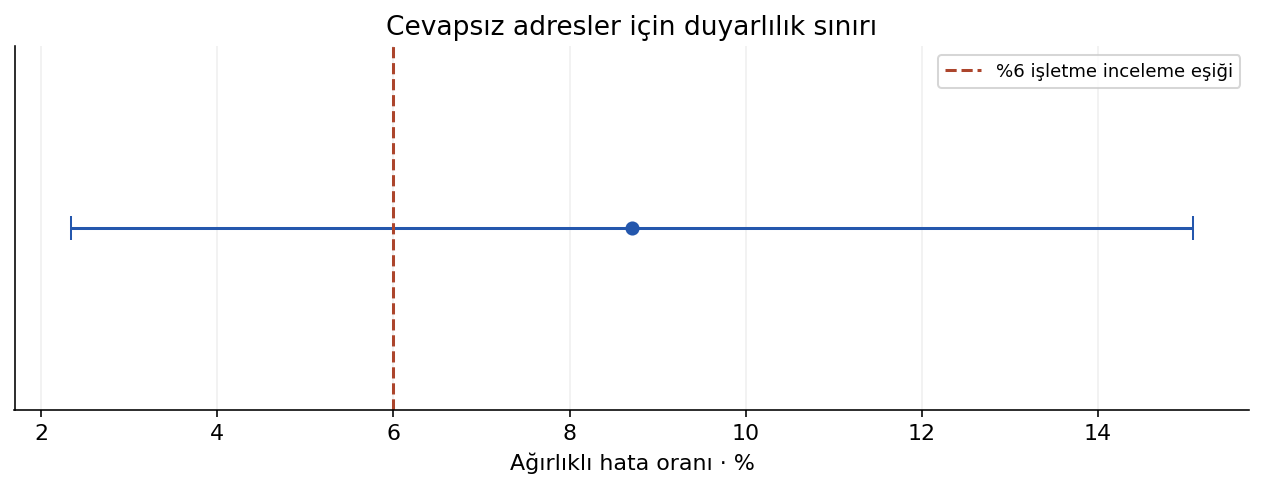

In [3]:
result = inventory_audit('nonresponse')
print_result(result)
plt.show()


## Karar notu

Önce tam veride %6 eşiğinin aralık içinde kalıp kalmadığını söyle. Sonra eksik veri senaryosunda hangi denetim kayıtlarını takip edeceğini ve nedenini yaz.

- Adres evreni paylarını hesapta kullan.
- Yaklaşık güven aralığı ile eksik veri sınırını ayrı adlandır.
- Eşik aralık içindeyse veri toplama veya takip öner.